<a href="https://colab.research.google.com/github/samsyed004/CV-lab/blob/main/lab07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 07 — Improving HOG-Based Medical Image Classification with a Genetic Algorithm

**Dataset:** BloodMNIST (8 blood-cell classes; official fixed train/validation/test split). You can switch to `pathmnist` or `pneumoniamnist` with one config variable.


 Setup and configuration

In [1]:
!pip install -q medmnist scikit-image opencv-python-headless tabulate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 3.9 MB/s eta 0:00:00


In [2]:
import os, time, json, random, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                              cohen_kappa_score, matthews_corrcoef, confusion_matrix)
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- dataset ----------------
DATASET_FLAG = "bloodmnist"      # "bloodmnist", "pathmnist" or "pneumoniamnist"
NATIVE_SIZE = 128                # MedMNIST+ native resolution to download (28/64/128/224)
IMG_SIZE = 128                   # resolution used for HOG
DATASET_REF = ("Yang J. et al., MedMNIST v2 - A large-scale lightweight benchmark for 2D and 3D biomedical image "
               "classification, Scientific Data 10, 41 (2023). BloodMNIST is derived from Acevedo A. et al., "
               "A dataset of microscopic peripheral blood cell images, Data in Brief 30 (2020). https://medmnist.com")

# ---------------- HOG (Table 1) ----------------
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys")

# ---------------- SVM ----------------
C_GRID = [1, 10, 100]            # tuned on the validation set for both systems

# ---------------- Genetic algorithm ----------------
LAMBDA = 0.05                    # feature-selection penalty weight
MIN_FEATURES = 50                # candidates with fewer features are invalid
GA_TRAIN_N, GA_VAL_N = 1500, 1000    # subsample sizes used inside the fitness function
ELITE, TOURNAMENT = 2, 3
GA_SETTINGS = {                  # at least two settings are compared (Task requirement)
    "GA-1": dict(pop_size=20, n_gens=15, p_mut=0.005, p_cross=0.8),
    "GA-2": dict(pop_size=30, n_gens=15, p_mut=0.020, p_cross=0.8),
}

FAST_MODE = False                # True = tiny GA for a quick smoke test (not for final results)
if FAST_MODE:
    GA_TRAIN_N, GA_VAL_N = 600, 400
    GA_SETTINGS = {"GA-1": dict(pop_size=8, n_gens=4, p_mut=0.005, p_cross=0.8),
                   "GA-2": dict(pop_size=10, n_gens=4, p_mut=0.020, p_cross=0.8)}

OUT = "/content/lab07_outputs"
os.makedirs(OUT, exist_ok=True)

## 1. Dataset (Task 1)

In [3]:
import medmnist
from medmnist import INFO

info = INFO[DATASET_FLAG]
DataClass = getattr(medmnist, info["python_class"])
class_names = [info["label"][str(i)] for i in range(len(info["label"]))]
DATASET_NAME = info["python_class"]

def load_split(split):
    try:
        ds = DataClass(split=split, download=True, size=NATIVE_SIZE)
    except TypeError:                       # older medmnist without the size argument (28x28 only)
        ds = DataClass(split=split, download=True)
    return ds.imgs, ds.labels.ravel().astype(int)

data_raw = {s: load_split(s) for s in ["train", "val", "test"]}
print(DATASET_NAME, "| classes:", class_names)
print("Reference:", DATASET_REF)
for s, (im, lb) in data_raw.items():
    print(f"  {s:5s}: images {im.shape}, labels {lb.shape}")

100%|██████████| 569M/569M [03:35<00:00, 2.65MB/s]


BloodMNIST | classes: ['basophil', 'eosinophil', 'erythroblast', 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Reference: Yang J. et al., MedMNIST v2 - A large-scale lightweight benchmark for 2D and 3D biomedical image classification, Scientific Data 10, 41 (2023). BloodMNIST is derived from Acevedo A. et al., A dataset of microscopic peripheral blood cell images, Data in Brief 30 (2020). https://medmnist.com
  train: images (11959, 128, 128, 3), labels (11959,)
  val  : images (1712, 128, 128, 3), labels (1712,)
  test : images (3421, 128, 128, 3), labels (3421,)


## 2. Preprocessing and fixed train / validation / test split (Task 2)

Images are converted to grayscale, resized to the common HOG resolution and scaled to [0, 1]. The official MedMNIST split is used for **every** approach, so all systems see identical data.

,train,val,test
Total,11959,1712,3421
basophil,852,122,244
eosinophil,2181,312,624
erythroblast,1085,155,311
"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",2026,290,579
lymphocyte,849,122,243
monocyte,993,143,284
neutrophil,2330,333,666
platelet,1643,235,470


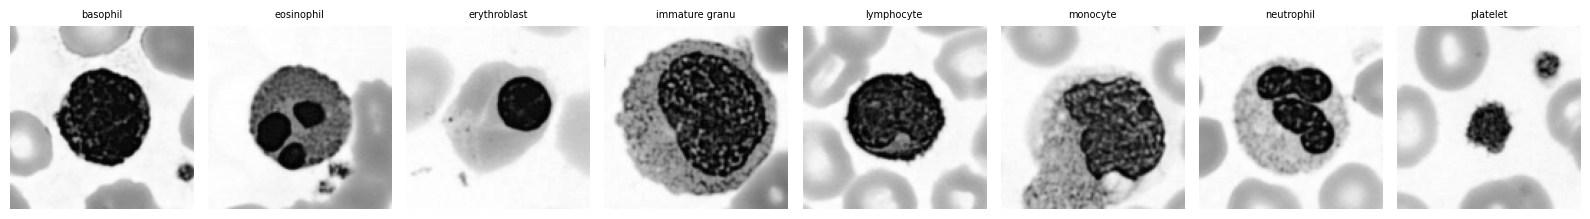

In [4]:
def preprocess(img):
    if img.ndim == 3 and img.shape[2] == 3:
        img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    elif img.ndim == 3:
        img = img[..., 0]
    if img.shape[0] != IMG_SIZE or img.shape[1] != IMG_SIZE:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC)
    return img.astype(np.float32) / 255.0

gray, y = {}, {}
for s, (im, lb) in data_raw.items():
    gray[s] = np.stack([preprocess(a) for a in im]); y[s] = lb
K = len(class_names)

split_df = pd.DataFrame({s: [len(y[s])] + [int((y[s] == k).sum()) for k in range(K)] for s in gray},
                        index=["Total"] + class_names)
display(split_df)

fig, axes = plt.subplots(1, K, figsize=(2 * K, 2.4))
for k in range(K):
    axes[k].imshow(gray["train"][np.where(y["train"] == k)[0][0]], cmap="gray"); axes[k].axis("off")
    axes[k].set_title(class_names[k][:14], fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/dataset_samples.png", dpi=130); plt.show()

## 3. HOG feature extraction (Task 4)

In [5]:
def hog_one(im):
    return hog(im, feature_vector=True, **HOG_PARAMS)

t0 = time.time()
X = {}
for s in ["train", "val", "test"]:
    X[s] = np.array(Parallel(n_jobs=-1, batch_size=64)(delayed(hog_one)(im) for im in gray[s]), dtype=np.float32)
hog_time_total = time.time() - t0
n_images_total = sum(len(v) for v in X.values())
hog_ms_per_image = hog_time_total / n_images_total * 1000
N_FEAT = X["train"].shape[1]
print("HOG feature matrix shapes:", {s: X[s].shape for s in X})
print(f"Number of HOG features: {N_FEAT} | extraction time {hog_time_total:.1f}s ({hog_ms_per_image:.2f} ms/image)")

HOG feature matrix shapes: {'train': (11959, 8100), 'val': (1712, 8100), 'test': (3421, 8100)}
Number of HOG features: 8100 | extraction time 142.8s (8.36 ms/image)


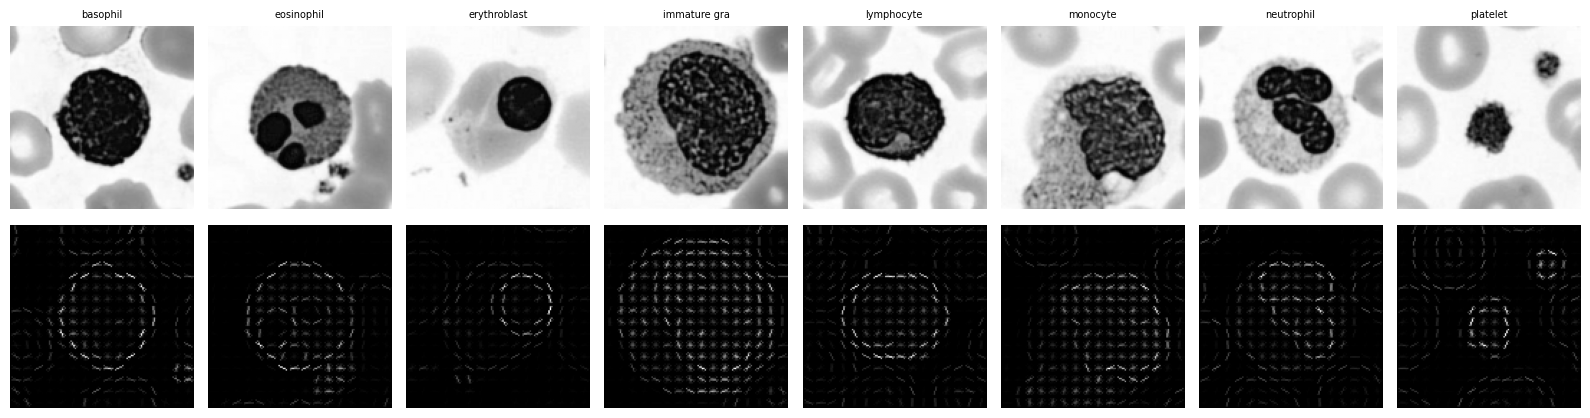

In [6]:
# HOG visualization of one representative image per class
fig, axes = plt.subplots(2, min(K, 8), figsize=(2 * min(K, 8), 4.4))
for k in range(min(K, 8)):
    im = gray["train"][np.where(y["train"] == k)[0][0]]
    _, h = hog(im, visualize=True, **HOG_PARAMS)
    axes[0][k].imshow(im, cmap="gray"); axes[0][k].set_title(class_names[k][:12], fontsize=7)
    axes[1][k].imshow(h, cmap="gray")
    axes[0][k].axis("off"); axes[1][k].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/hog_visualization.png", dpi=130); plt.show()

## 4. Helpers: metrics and an exact fast RBF-SVM

`rbf_gram` builds the RBF kernel with matrix multiplication (BLAS), and the SVM is trained with `kernel="precomputed"`. With `gamma = 1 / (n_features · X.var())` this is **exactly** scikit-learn's `SVC(kernel="rbf", gamma="scale")`, but much faster for repeated GA fitness evaluations. Both the baseline and the GA model use this same code path, so computation times are comparable.

In [7]:
def rbf_gram(A, B, gamma):
    a2 = (A * A).sum(1)[:, None]
    b2 = (B * B).sum(1)[None, :]
    d2 = np.maximum(a2 + b2 - 2.0 * (A @ B.T), 0.0)
    return np.exp(-gamma * d2)

def scale_gamma(A):
    return 1.0 / (A.shape[1] * A.var())

def full_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(K)))
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - tp - fp - fn
    spec = np.where(tn + fp > 0, tn / np.maximum(tn + fp, 1), 0.0)
    return {
        "Accuracy (%)": 100 * accuracy_score(y_true, y_pred),
        "Precision (Macro, %)": 100 * precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (Macro, %)": 100 * recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro-F1 (%)": 100 * f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted-F1 (%)": 100 * f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(y_true, y_pred),
        "Specificity (Macro, %)": 100 * spec.mean(),
        "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
        "Matthews correlation coefficient": matthews_corrcoef(y_true, y_pred),
    }

# sanity check: precomputed-kernel SVM == sklearn RBF SVM on a small subset
sub = np.random.default_rng(0).choice(len(X["train"]), 600, replace=False)
A = X["train"][sub]; g = scale_gamma(A)
p_ref = SVC(kernel="rbf", gamma="scale", C=10).fit(A, y["train"][sub]).predict(X["val"][:300])
svm_chk = SVC(kernel="precomputed", C=10).fit(rbf_gram(A, A, g).astype(np.float64), y["train"][sub])
p_pre = svm_chk.predict(rbf_gram(X["val"][:300], A, g).astype(np.float64))
print(f"Agreement between sklearn RBF-SVM and precomputed-kernel SVM: {(p_ref == p_pre).mean() * 100:.1f}%")

Agreement between sklearn RBF-SVM and precomputed-kernel SVM: 100.0%


In [8]:
def train_rbf_svm(Xtr, ytr, Xva, yva, idx=None, label=""):
    """Train an RBF-SVM on the (optionally feature-selected) data, tuning C on the validation set."""
    t0 = time.time()
    A = Xtr if idx is None else np.ascontiguousarray(Xtr[:, idx])
    B = Xva if idx is None else np.ascontiguousarray(Xva[:, idx])
    gamma = scale_gamma(A)
    Ktr = rbf_gram(A, A, gamma).astype(np.float64)
    Kva = rbf_gram(B, A, gamma).astype(np.float64)
    gram_time = time.time() - t0

    rows, best = [], None
    for C in C_GRID:
        t1 = time.time()
        svm = SVC(kernel="precomputed", C=C).fit(Ktr, ytr)
        fit_time = time.time() - t1
        pred = svm.predict(Kva)
        f1 = f1_score(yva, pred, average="macro"); acc = accuracy_score(yva, pred)
        rows.append({"C": C, "Val macro-F1 (%)": round(100 * f1, 2), "Val accuracy (%)": round(100 * acc, 2),
                     "Fit time (s)": round(fit_time, 1)})
        if best is None or f1 > best["f1"]:
            best = {"C": C, "svm": svm, "f1": f1, "acc": acc, "fit_time": fit_time}
    del Ktr, Kva
    print(f"[{label}] validation C-tuning:")
    display(pd.DataFrame(rows))
    return {"svm": best["svm"], "C": best["C"], "idx": idx, "A": A, "gamma": gamma,
            "val_f1": best["f1"], "val_acc": best["acc"],
            "train_time": gram_time + best["fit_time"], "n_features": A.shape[1]}

def predict_rbf_svm(model, Xnew):
    t0 = time.time()
    B = Xnew if model["idx"] is None else np.ascontiguousarray(Xnew[:, model["idx"]])
    pred = model["svm"].predict(rbf_gram(B, model["A"], model["gamma"]).astype(np.float64))
    return pred, time.time() - t0

## 5. Baseline: HOG + SVM using all features (Task 3)

Only the validation set is used here (to tune `C`). Test predictions are produced in Section 10.

In [9]:
baseline = train_rbf_svm(X["train"], y["train"], X["val"], y["val"], idx=None, label="Baseline HOG+SVM")
print(f"Baseline: {baseline['n_features']} features | best C = {baseline['C']} | "
      f"val macro-F1 = {100 * baseline['val_f1']:.2f}% | training time = {baseline['train_time']:.1f}s")

[Baseline HOG+SVM] validation C-tuning:


,C,Val macro-F1 (%),Val accuracy (%),Fit time (s)
0,1,78.95,79.96,4.2
1,10,80.96,81.66,3.7
2,100,80.96,81.66,3.7


Baseline: 8100 features | best C = 10 | val macro-F1 = 80.96% | training time = 36.9s


## 6. Genetic algorithm for feature selection (Tasks 5 and 6)

* **Chromosome:** binary mask over the HOG features (1 = feature kept)
* **Initialization:** random masks with different densities (30–70 % ones); individual 0 keeps all features
* **Fitness:** validation macro-F1 − λ · (selected / total), evaluated with an RBF-SVM trained on a stratified training subsample
* **Selection:** tournament selection (size 3), with elitism
* **Crossover:** uniform crossover
* **Mutation:** per-gene bit flip with probability `p_mut`

In [10]:
# stratified subsamples used only inside the GA fitness function
ga_tr_idx = np.arange(len(y["train"])) if GA_TRAIN_N >= len(y["train"]) else \
    train_test_split(np.arange(len(y["train"])), train_size=GA_TRAIN_N, stratify=y["train"], random_state=SEED)[0]
ga_va_idx = np.arange(len(y["val"])) if GA_VAL_N >= len(y["val"]) else \
    train_test_split(np.arange(len(y["val"])), train_size=GA_VAL_N, stratify=y["val"], random_state=SEED)[0]
Xga_tr, yga_tr = X["train"][ga_tr_idx], y["train"][ga_tr_idx]
Xga_va, yga_va = X["val"][ga_va_idx], y["val"][ga_va_idx]
C_GA = baseline["C"]          # the GA uses the C tuned for the baseline
print("GA fitness subsample: train", Xga_tr.shape, " val", Xga_va.shape, " C =", C_GA)

def evaluate_mask(mask):
    idx = np.flatnonzero(mask)
    if len(idx) < MIN_FEATURES:
        return -1.0, 0.0
    A = Xga_tr[:, idx]; B = Xga_va[:, idx]
    gamma = scale_gamma(A)
    svm = SVC(kernel="precomputed", C=C_GA).fit(rbf_gram(A, A, gamma).astype(np.float64), yga_tr)
    pred = svm.predict(rbf_gram(B, A, gamma).astype(np.float64))
    f1 = f1_score(yga_va, pred, average="macro")
    return f1 - LAMBDA * len(idx) / N_FEAT, f1

def run_ga(pop_size, n_gens, p_mut, p_cross, seed=SEED, name="GA"):
    rng = np.random.default_rng(seed)
    t_start = time.time()
    pop = np.stack([rng.random(N_FEAT) < d for d in rng.uniform(0.3, 0.7, pop_size)])
    pop[0] = True                                   # the full feature set is part of the initial population
    cache, history = {}, []
    best_overall = {"fit": -9, "mask": None, "f1": 0}

    def fitness_of(ind):
        key = ind.tobytes()
        if key not in cache:
            cache[key] = evaluate_mask(ind)
        return cache[key]

    for gen in range(n_gens + 1):
        res = [fitness_of(ind) for ind in pop]
        fits = np.array([r[0] for r in res]); f1s = np.array([r[1] for r in res])
        nfe = pop.sum(1)
        b = int(np.argmax(fits))
        if fits[b] > best_overall["fit"]:
            best_overall = {"fit": float(fits[b]), "mask": pop[b].copy(), "f1": float(f1s[b])}
        history.append({"generation": gen, "best_fitness": fits.max(), "mean_fitness": fits.mean(),
                        "best_f1": f1s[b], "best_n_features": int(nfe[b]), "mean_n_features": nfe.mean(),
                        "elapsed_s": time.time() - t_start})
        print(f"[{name}] gen {gen:2d} | best fitness {fits.max():.4f} (F1 {f1s[b]:.4f}, {nfe[b]} feats) | "
              f"mean fitness {fits.mean():.4f} | {time.time() - t_start:.0f}s")
        if gen == n_gens:
            break
        order = np.argsort(-fits)
        new_pop = [pop[i].copy() for i in order[:ELITE]]                      # elitism
        while len(new_pop) < pop_size:
            parents = []
            for _ in range(2):                                                # tournament selection
                cand = rng.integers(0, pop_size, TOURNAMENT)
                parents.append(pop[cand[np.argmax(fits[cand])]])
            c1, c2 = parents[0].copy(), parents[1].copy()
            if rng.random() < p_cross:                                        # uniform crossover
                sw = rng.random(N_FEAT) < 0.5
                c1[sw], c2[sw] = parents[1][sw], parents[0][sw]
            for c in (c1, c2):                                                # bit-flip mutation
                c ^= rng.random(N_FEAT) < p_mut
                if len(new_pop) < pop_size:
                    new_pop.append(c)
        pop = np.stack(new_pop)

    return {"mask": best_overall["mask"], "fitness": best_overall["fit"], "f1_subsample": best_overall["f1"],
            "history": pd.DataFrame(history), "time_s": time.time() - t_start, "evaluations": len(cache)}

GA fitness subsample: train (1500, 8100)  val (1000, 8100)  C = 10


### Run the GA with each setting

In [11]:
ga_results = {}
for name, cfg in GA_SETTINGS.items():
    print(f"\n===== {name}: {cfg} =====")
    ga_results[name] = run_ga(**cfg, name=name)
    r = ga_results[name]
    print(f"{name} finished in {r['time_s']:.0f}s | {r['evaluations']} fitness evaluations | "
          f"selected {int(r['mask'].sum())} / {N_FEAT} features")


===== GA-1: {'pop_size': 20, 'n_gens': 15, 'p_mut': 0.005, 'p_cross': 0.8} =====
[GA-1] gen  0 | best fitness 0.6243 (F1 0.6509, 4298 feats) | mean fitness 0.6093 | 17s
[GA-1] gen  1 | best fitness 0.6262 (F1 0.6566, 4930 feats) | mean fitness 0.6167 | 32s
[GA-1] gen  2 | best fitness 0.6295 (F1 0.6578, 4584 feats) | mean fitness 0.6217 | 47s
[GA-1] gen  3 | best fitness 0.6295 (F1 0.6578, 4584 feats) | mean fitness 0.6249 | 63s
[GA-1] gen  4 | best fitness 0.6393 (F1 0.6667, 4437 feats) | mean fitness 0.6277 | 79s
[GA-1] gen  5 | best fitness 0.6393 (F1 0.6667, 4437 feats) | mean fitness 0.6296 | 95s
[GA-1] gen  6 | best fitness 0.6424 (F1 0.6700, 4468 feats) | mean fitness 0.6319 | 110s
[GA-1] gen  7 | best fitness 0.6443 (F1 0.6720, 4488 feats) | mean fitness 0.6331 | 126s
[GA-1] gen  8 | best fitness 0.6448 (F1 0.6725, 4484 feats) | mean fitness 0.6370 | 141s
[GA-1] gen  9 | best fitness 0.6468 (F1 0.6747, 4527 feats) | mean fitness 0.6378 | 156s
[GA-1] gen 10 | best fitness 0.647

## 7. Train SVMs on the selected features and select the best GA setting — validation set only (Task 7)

In [12]:
ga_models, sel_rows = {}, []
for name, r in ga_results.items():
    idx = np.flatnonzero(r["mask"])
    m = train_rbf_svm(X["train"], y["train"], X["val"], y["val"], idx=idx, label=f"{name}-HOG+SVM")
    ga_models[name] = m
    sel_rows.append({"GA setting": name, **{k: v for k, v in GA_SETTINGS[name].items()},
                     "Selected features": m["n_features"],
                     "Reduction (%)": round(100 * (1 - m["n_features"] / N_FEAT), 1),
                     "GA search time (s)": round(r["time_s"], 1), "Best C": m["C"],
                     "Val macro-F1 (%)": round(100 * m["val_f1"], 2), "Val accuracy (%)": round(100 * m["val_acc"], 2)})

base_row = {"GA setting": "Baseline (no GA)", "Selected features": N_FEAT, "Reduction (%)": 0.0,
            "Best C": baseline["C"], "Val macro-F1 (%)": round(100 * baseline["val_f1"], 2),
            "Val accuracy (%)": round(100 * baseline["val_acc"], 2)}
ga_setting_df = pd.DataFrame(sel_rows)
# model selection: highest validation macro-F1, ties broken by fewer features
BEST_GA = ga_setting_df.sort_values(["Val macro-F1 (%)", "Selected features"], ascending=[False, True]).iloc[0]["GA setting"]
ga_compare_df = pd.concat([pd.DataFrame([base_row]), ga_setting_df], ignore_index=True)
ga_compare_df.to_csv(f"{OUT}/table_ga_settings_validation.csv", index=False)
print("Validation-set comparison of GA settings (used for model selection):")
display(ga_compare_df)
print("Selected GA setting for final evaluation:", BEST_GA)

[GA-1-HOG+SVM] validation C-tuning:


,C,Val macro-F1 (%),Val accuracy (%),Fit time (s)
0,1,78.74,79.61,3.1
1,10,80.09,80.72,3.2
2,100,80.09,80.72,3.2


[GA-2-HOG+SVM] validation C-tuning:


,C,Val macro-F1 (%),Val accuracy (%),Fit time (s)
0,1,78.15,78.86,2.9
1,10,79.96,80.49,3.2
2,100,79.96,80.49,3.2


Validation-set comparison of GA settings (used for model selection):


,GA setting,Selected features,Reduction (%),Best C,Val macro-F1 (%),Val accuracy (%),pop_size,n_gens,p_mut,p_cross,GA search time (s)
0,Baseline (no GA),8100,0.0,10,80.96,81.66,NaN,NaN,NaN,NaN,NaN
1,GA-1,4531,44.1,10,80.09,80.72,20.0,15.0,0.005,0.8,246.9
2,GA-2,3825,52.8,10,79.96,80.49,30.0,15.0,0.020,0.8,339.9


Selected GA setting for final evaluation: GA-1


## 8. GA fitness across generations and feature counts (Task 9)

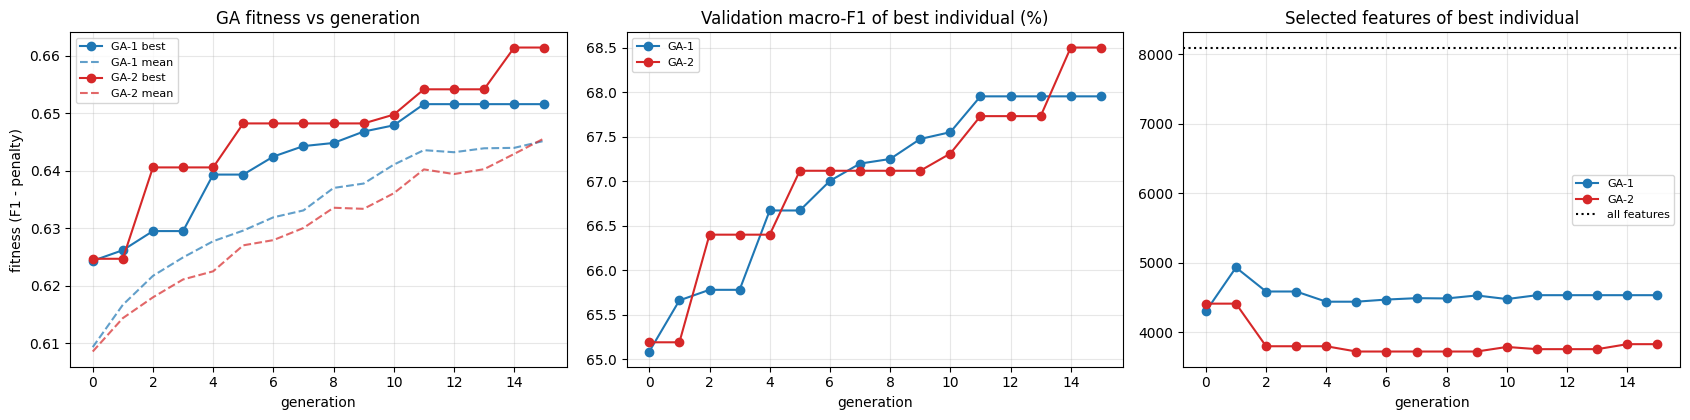

In [13]:
colors = {"GA-1": "#1f77b4", "GA-2": "#d62728"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for name, r in ga_results.items():
    h = r["history"]; c = colors.get(name)
    axes[0].plot(h["generation"], h["best_fitness"], "-o", color=c, label=f"{name} best")
    axes[0].plot(h["generation"], h["mean_fitness"], "--", color=c, alpha=0.7, label=f"{name} mean")
    axes[1].plot(h["generation"], h["best_f1"] * 100, "-o", color=c, label=name)
    axes[2].plot(h["generation"], h["best_n_features"], "-o", color=c, label=name)
axes[0].set_title("GA fitness vs generation"); axes[0].set_ylabel("fitness (F1 - penalty)")
axes[1].set_title("Validation macro-F1 of best individual (%)")
axes[2].set_title("Selected features of best individual"); axes[2].axhline(N_FEAT, color="k", ls=":", label="all features")
for ax in axes: ax.set_xlabel("generation"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/ga_fitness_curves.png", dpi=140); plt.show()

history_all = pd.concat([r["history"].assign(setting=n) for n, r in ga_results.items()])
history_all.to_csv(f"{OUT}/ga_history.csv", index=False)

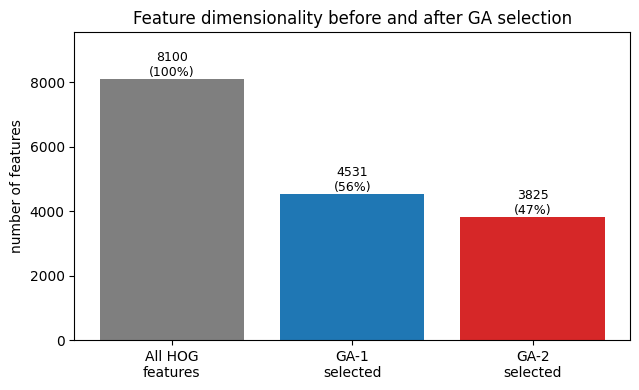

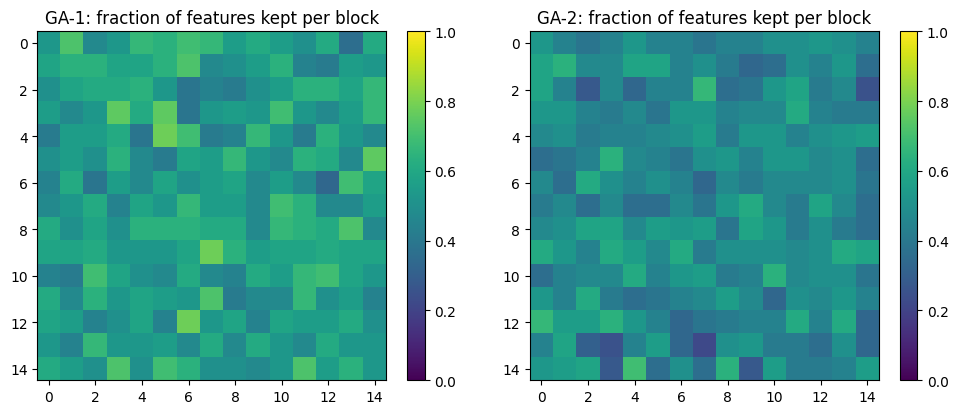

In [14]:
# number of features before / after selection
fig, ax = plt.subplots(figsize=(6.5, 4))
labels = ["All HOG\nfeatures"] + [f"{n}\nselected" for n in ga_results]
vals = [N_FEAT] + [ga_models[n]["n_features"] for n in ga_results]
bars = ax.bar(labels, vals, color=["#7f7f7f"] + [colors.get(n, "#2ca02c") for n in ga_results])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({100 * v / N_FEAT:.0f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("number of features"); ax.set_title("Feature dimensionality before and after GA selection")
ax.set_ylim(0, N_FEAT * 1.18); plt.tight_layout(); plt.savefig(f"{OUT}/feature_counts.png", dpi=140); plt.show()

# where in the image do the selected features come from? (skimage layout: block_y, block_x, cell_y, cell_x, orientation)
ny = nx = IMG_SIZE // HOG_PARAMS["pixels_per_cell"][0] - HOG_PARAMS["cells_per_block"][0] + 1
cby, cbx = HOG_PARAMS["cells_per_block"]
fig, axes = plt.subplots(1, len(ga_results), figsize=(5 * len(ga_results), 4.2))
axes = np.atleast_1d(axes)
for ax, (n, r) in zip(axes, ga_results.items()):
    frac = r["mask"].reshape(ny, nx, cby, cbx, HOG_PARAMS["orientations"]).mean(axis=(2, 3, 4))
    im = ax.imshow(frac, cmap="viridis", vmin=0, vmax=1); ax.set_title(f"{n}: fraction of features kept per block")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(f"{OUT}/selected_feature_map.png", dpi=140); plt.show()

## 9. Table 1 — experimental configuration

In [15]:
table1 = pd.DataFrame([
    ("Medical dataset", f"{DATASET_NAME}", f"{DATASET_NAME}"),
    ("Image resolution", f"{IMG_SIZE} x {IMG_SIZE}", f"{IMG_SIZE} x {IMG_SIZE}"),
    ("HOG orientations", HOG_PARAMS["orientations"], HOG_PARAMS["orientations"]),
    ("Pixels per cell", "{0} x {0}".format(HOG_PARAMS["pixels_per_cell"][0]), "{0} x {0}".format(HOG_PARAMS["pixels_per_cell"][0])),
    ("Cells per block", "{0} x {0}".format(HOG_PARAMS["cells_per_block"][0]), "{0} x {0}".format(HOG_PARAMS["cells_per_block"][0])),
    ("Block normalization", HOG_PARAMS["block_norm"], HOG_PARAMS["block_norm"]),
    ("Feature selection", "None", f"Genetic Algorithm (best setting: {BEST_GA})"),
    ("Number of features", N_FEAT, ga_models[BEST_GA]["n_features"]),
    ("Classifier", "SVM", "SVM"),
    ("SVM kernel", "RBF", "RBF"),
    ("Hyperparameter tuning", f"Validation set (C in {C_GRID})", f"Validation set (C in {C_GRID})"),
    ("Data split", "Identical fixed split (official train/val/test)", "Identical fixed split (official train/val/test)"),
    ("Random seed", SEED, SEED),
], columns=["Parameter", "Baseline: HOG + SVM", "Proposed: GA-HOG + SVM"])
table1.to_csv(f"{OUT}/table1_configuration.csv", index=False)
ga_param_df = pd.DataFrame([{"Setting": n, **cfg, "lambda": LAMBDA, "elitism": ELITE, "tournament size": TOURNAMENT,
                             "crossover": "uniform", "fitness subsample (train/val)": f"{len(yga_tr)}/{len(yga_va)}"}
                            for n, cfg in GA_SETTINGS.items()])
ga_param_df.to_csv(f"{OUT}/table_ga_parameters.csv", index=False)
display(table1); display(ga_param_df)

,Parameter,Baseline: HOG + SVM,Proposed: GA-HOG + SVM
0,Medical dataset,BloodMNIST,BloodMNIST
1,Image resolution,128 x 128,128 x 128
2,HOG orientations,9,9
3,Pixels per cell,8 x 8,8 x 8
4,Cells per block,2 x 2,2 x 2
5,Block normalization,L2-Hys,L2-Hys
6,Feature selection,None,Genetic Algorithm (best setting: GA-1)
7,Number of features,8100,4531
8,Classifier,SVM,SVM
9,SVM kernel,RBF,RBF


,Setting,pop_size,n_gens,p_mut,p_cross,lambda,elitism,tournament size,crossover,fitness subsample (train/val)
0,GA-1,20,15,0.005,0.8,0.05,2,3,uniform,1500/1000
1,GA-2,30,15,0.020,0.8,0.05,2,3,uniform,1500/1000


## 10. Final evaluation on the TEST set (after model selection is complete) — Tables 2 and 3 (Task 8)

In [16]:
final_ga = ga_models[BEST_GA]

pred_base, t_inf_base = predict_rbf_svm(baseline, X["test"])
pred_ga, t_inf_ga = predict_rbf_svm(final_ga, X["test"])
yt = y["test"]

m_base, m_ga = full_metrics(yt, pred_base), full_metrics(yt, pred_ga)
table2 = pd.DataFrame({"Metric": list(m_base), "HOG + SVM (Baseline)": list(m_base.values()),
                       "GA-HOG + SVM (Proposed)": list(m_ga.values())})
table2["Improvement"] = table2["GA-HOG + SVM (Proposed)"] - table2["HOG + SVM (Baseline)"]
table2_disp = table2.copy()
for c in table2_disp.columns[1:]:
    table2_disp[c] = table2_disp[c].round(3)
table2.to_csv(f"{OUT}/table2_performance.csv", index=False)
print(f"TABLE 2 - test-set performance (proposed = {BEST_GA}). Improvement = proposed - baseline "
      "(percentage points for % metrics; absolute difference for kappa/MCC). Specificity is one-vs-rest per class, macro-averaged.")
display(table2_disp)

TABLE 2 - test-set performance (proposed = GA-1). Improvement = proposed - baseline (percentage points for % metrics; absolute difference for kappa/MCC). Specificity is one-vs-rest per class, macro-averaged.


,Metric,HOG + SVM (Baseline),GA-HOG + SVM (Proposed),Improvement
0,Accuracy (%),80.327,79.830,-0.497
1,"Precision (Macro, %)",80.770,80.406,-0.364
2,"Recall (Macro, %)",78.258,77.884,-0.374
3,Macro-F1 (%),79.300,78.905,-0.395
4,Weighted-F1 (%),80.231,79.724,-0.507
5,Balanced accuracy (%),78.258,77.884,-0.374
6,"Specificity (Macro, %)",97.098,97.022,-0.077
7,Cohen's kappa,0.769,0.763,-0.006
8,Matthews correlation coefficient,0.770,0.764,-0.006


In [17]:
n_test = len(yt)
table3 = pd.DataFrame([
    ("Number of features", N_FEAT, final_ga["n_features"]),
    ("Feature reduction (%)", 0.0, round(100 * (1 - final_ga["n_features"] / N_FEAT), 1)),
    ("GA feature-selection time (s, one-off)", 0.0, round(ga_results[BEST_GA]["time_s"], 1)),
    ("SVM training time (s)", round(baseline["train_time"], 1), round(final_ga["train_time"], 1)),
    ("Classifier inference time (ms/image)", round(t_inf_base / n_test * 1000, 3), round(t_inf_ga / n_test * 1000, 3)),
    ("HOG extraction time (ms/image)", round(hog_ms_per_image, 3), round(hog_ms_per_image, 3)),
    ("Total inference time (ms/image)", round(t_inf_base / n_test * 1000 + hog_ms_per_image, 3),
     round(t_inf_ga / n_test * 1000 + hog_ms_per_image, 3)),
    ("Support vectors", int(baseline["svm"].n_support_.sum()), int(final_ga["svm"].n_support_.sum())),
    ("Selected SVM C", baseline["C"], final_ga["C"]),
], columns=["Item", "HOG + SVM (Baseline)", "GA-HOG + SVM (Proposed)"]).astype(object)
table3.to_csv(f"{OUT}/table3_computation.csv", index=False)
print("TABLE 3 - features and computational cost")
display(table3)

TABLE 3 - features and computational cost


,Item,HOG + SVM (Baseline),GA-HOG + SVM (Proposed)
0,Number of features,8100.0,4531.0
1,Feature reduction (%),0.0,44.1
2,"GA feature-selection time (s, one-off)",0.0,246.9
3,SVM training time (s),36.9,26.8
4,Classifier inference time (ms/image),4.266,2.822
5,HOG extraction time (ms/image),8.357,8.357
6,Total inference time (ms/image),12.623,11.179
7,Support vectors,10772.0,10731.0
8,Selected SVM C,10.0,10.0


In [18]:
from scipy.stats import chi2

# McNemar test + bootstrap CI for the macro-F1 difference
ok_b, ok_g = pred_base == yt, pred_ga == yt
b01 = int((ok_b & ~ok_g).sum()); b10 = int((~ok_b & ok_g).sum())
mcnemar_stat = (abs(b01 - b10) - 1) ** 2 / (b01 + b10) if (b01 + b10) > 0 else 0.0
mcnemar_p = float(chi2.sf(mcnemar_stat, 1)) if (b01 + b10) > 0 else 1.0

rng = np.random.default_rng(SEED)
diffs = []
for _ in range(1000):
    ii = rng.integers(0, n_test, n_test)
    diffs.append(f1_score(yt[ii], pred_ga[ii], average="macro") - f1_score(yt[ii], pred_base[ii], average="macro"))
ci_low, ci_high = 100 * np.percentile(diffs, 2.5), 100 * np.percentile(diffs, 97.5)
delta_f1 = m_ga["Macro-F1 (%)"] - m_base["Macro-F1 (%)"]
print(f"Macro-F1 difference (GA - baseline): {delta_f1:+.2f} pp, 95% bootstrap CI [{ci_low:+.2f}, {ci_high:+.2f}]")
print(f"McNemar: baseline-only correct = {b01}, GA-only correct = {b10}, p = {mcnemar_p:.4f}")

Macro-F1 difference (GA - baseline): -0.40 pp, 95% bootstrap CI [-1.19, +0.41]
McNemar: baseline-only correct = 79, GA-only correct = 62, p = 0.1778


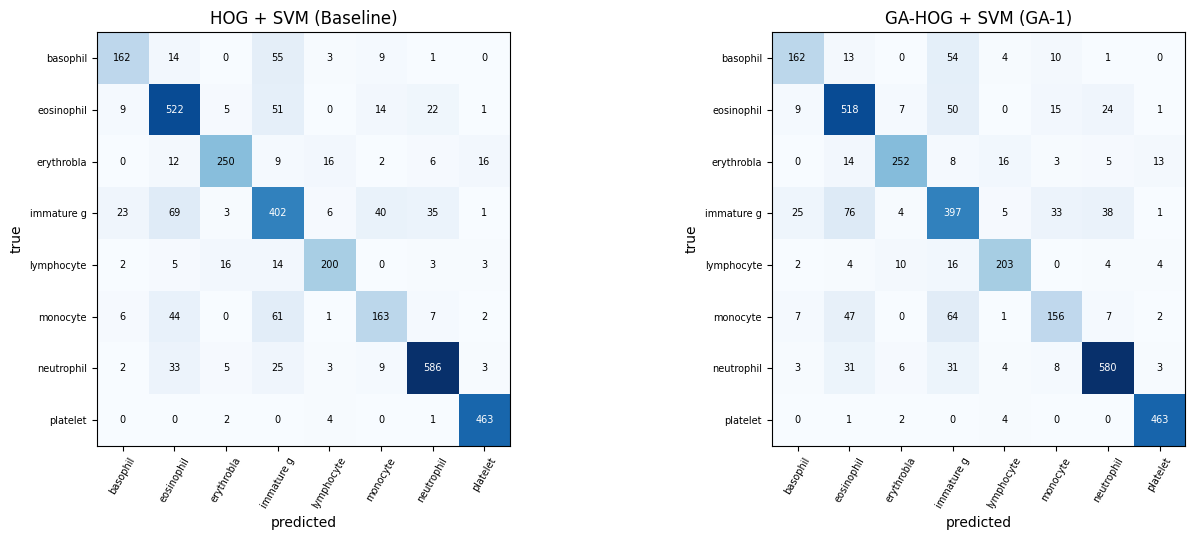

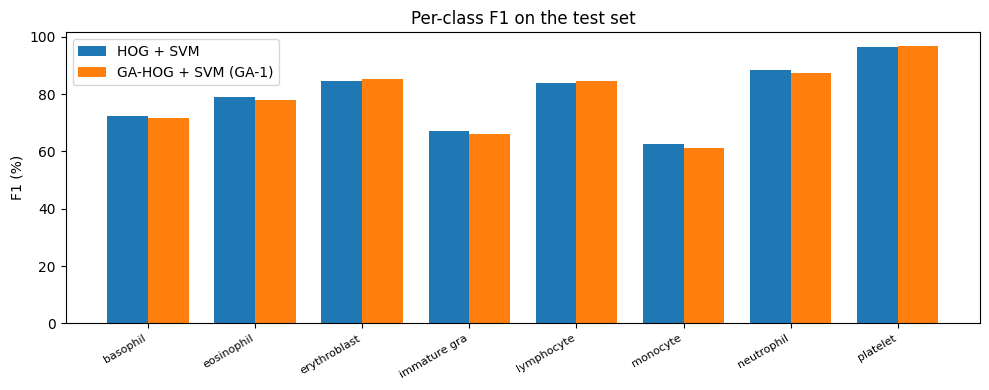

In [19]:
# confusion matrices and per-class F1
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (title, pred) in zip(axes, [("HOG + SVM (Baseline)", pred_base), (f"GA-HOG + SVM ({BEST_GA})", pred_ga)]):
    cm = confusion_matrix(yt, pred, labels=list(range(K)))
    ax.imshow(cm, cmap="Blues"); ax.set_title(title)
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xticklabels([n[:10] for n in class_names], rotation=60, fontsize=7); ax.set_yticklabels([n[:10] for n in class_names], fontsize=7)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrices.png", dpi=140); plt.show()

f1_b = f1_score(yt, pred_base, average=None, labels=list(range(K))) * 100
f1_g = f1_score(yt, pred_ga, average=None, labels=list(range(K))) * 100
fig, ax = plt.subplots(figsize=(10, 4)); x = np.arange(K); w = 0.38
ax.bar(x - w / 2, f1_b, w, label="HOG + SVM"); ax.bar(x + w / 2, f1_g, w, label=f"GA-HOG + SVM ({BEST_GA})")
ax.set_xticks(x); ax.set_xticklabels([n[:12] for n in class_names], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("F1 (%)"); ax.set_title("Per-class F1 on the test set"); ax.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/per_class_f1.png", dpi=140); plt.show()

### Automatic verdict (generated from the numbers above)

In [20]:
red = 100 * (1 - final_ga["n_features"] / N_FEAT)
if ci_low > 0:
    perf = f"IMPROVED macro-F1 by {delta_f1:+.2f} pp (95% CI excludes zero)"
elif delta_f1 > 0:
    perf = f"gave a slightly higher macro-F1 ({delta_f1:+.2f} pp) but the difference is NOT statistically reliable (95% CI [{ci_low:+.2f}, {ci_high:+.2f}])"
elif ci_high < 0:
    perf = f"REDUCED macro-F1 by {abs(delta_f1):.2f} pp (95% CI excludes zero)"
else:
    perf = f"gave comparable macro-F1 ({delta_f1:+.2f} pp, 95% CI [{ci_low:+.2f}, {ci_high:+.2f}], no reliable difference)"
verdict = (f"GA-based feature selection ({BEST_GA}) {perf}, while keeping {final_ga['n_features']} of {N_FEAT} features "
           f"({red:.1f}% reduction). McNemar p = {mcnemar_p:.4f}.")
print(verdict)

GA-based feature selection (GA-1) gave comparable macro-F1 (-0.40 pp, 95% CI [-1.19, +0.41], no reliable difference), while keeping 4531 of 8100 features (44.1% reduction). McNemar p = 0.1778.


## 11. Export results and generate the report

In [ ]:
def _fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "-"
    if isinstance(v, (float, np.floating)) and float(v).is_integer():
        return str(int(v))
    return str(v)

def md_table(df):
    return df.astype(object).apply(lambda col: col.map(_fmt)).to_markdown(index=False, disable_numparse=True)

improved = ci_low > 0
research_answer = ("Yes - the GA-selected subset classified better than the full feature set and used fewer features."
                   if improved and red > 0 else
                   "Partly - " + ("dimensionality was reduced with no reliable loss in performance, but a reliable performance gain was not demonstrated."
                                  if (ci_high >= 0 and red > 0 and delta_f1 > -1) else
                                  "the selected subset did not improve classification performance in this experiment."))
ga_time = ga_results[BEST_GA]["time_s"]
train_ratio = ga_time / max(baseline["train_time"], 1e-9)

report = f"""# Improving HOG-Based Medical Image Classification Using a Genetic Algorithm

## 1. Introduction and research question
HOG features describe local gradient structure but produce long, partly redundant vectors ({N_FEAT} features for a {IMG_SIZE}x{IMG_SIZE} image with the settings below). This lab tests whether a Genetic Algorithm (GA) used for feature selection can improve classification performance of HOG features while reducing their dimensionality.

**Research question:** Can GA-based feature selection improve the classification performance of HOG features while reducing feature dimensionality on medical images?

## 2. Dataset
{DATASET_NAME} ({K} classes: {", ".join(class_names)}). Official fixed split: {len(y["train"])} training, {len(y["val"])} validation and {len(y["test"])} test images, used identically for every approach. Reference: {DATASET_REF}

## 3. Methods
**Preprocessing:** grayscale conversion, resize to {IMG_SIZE}x{IMG_SIZE}, scaling to [0, 1].
**HOG:** {HOG_PARAMS["orientations"]} orientations, {HOG_PARAMS["pixels_per_cell"][0]}x{HOG_PARAMS["pixels_per_cell"][0]} pixels per cell, {HOG_PARAMS["cells_per_block"][0]}x{HOG_PARAMS["cells_per_block"][0]} cells per block, {HOG_PARAMS["block_norm"]} normalization.
**Baseline:** all HOG features with an RBF-SVM; C tuned on the validation set from {C_GRID}.
**Proposed (GA-HOG + SVM):** each chromosome is a binary mask over the {N_FEAT} HOG features. Fitness = validation macro-F1 - {LAMBDA} x (selected/total features), evaluated with an RBF-SVM trained on a stratified subsample ({len(yga_tr)} training / {len(yga_va)} validation images) for speed. Operators: random initial population (one individual keeps all features), tournament selection (size {TOURNAMENT}), uniform crossover, bit-flip mutation, elitism ({ELITE}). Two GA settings were compared on the validation set and the better one ({BEST_GA}) was carried to the test set.

## 4. Experimental setup (Table 1)
{md_table(table1)}

GA settings:

{md_table(ga_param_df)}

## 5. Results
### 5.1 GA setting selection (validation set)
{md_table(ga_compare_df)}

![GA fitness](ga_fitness_curves.png)
![Feature counts](feature_counts.png)
![Selected feature map](selected_feature_map.png)

### 5.2 Main comparison on the test set (Table 2)
Improvement = proposed - baseline (percentage points for % metrics). Specificity is one-vs-rest per class, macro-averaged.

{md_table(table2_disp)}

Macro-F1 difference: {delta_f1:+.2f} pp (95% bootstrap CI [{ci_low:+.2f}, {ci_high:+.2f}]); McNemar test p = {mcnemar_p:.4f} (baseline-only correct: {b01}, GA-only correct: {b10}).

![Confusion matrices](confusion_matrices.png)
![Per-class F1](per_class_f1.png)

### 5.3 Features and computational cost (Table 3)
{md_table(table3)}

## 6. Discussion
**Did GA selection help?** {verdict}

**Strengths.** The GA is a wrapper method: it optimises the real objective (macro-F1 of the final classifier) and needs no gradients. It reduces dimensionality, which lowers memory use and classifier inference cost, and the selected-feature map shows which image regions and orientations the classifier relies on. The penalty term gives an explicit trade-off between accuracy and compactness.

**Limitations.** The search is stochastic, so results depend on the seed and a single run cannot show how much of a difference is due to chance. The fitness uses a training subsample and the validation set, so the GA can overfit the validation data; this is why the test set was used only once after selection. Only one dataset and one HOG configuration were studied. The GA setting grid is small, and the penalty weight (lambda = {LAMBDA}) was not tuned.

**Computational cost.** The one-off GA search took {ga_time:.0f} s ({ga_results[BEST_GA]["evaluations"]} fitness evaluations), about {train_ratio:.1f} times the baseline SVM training time ({baseline["train_time"]:.0f} s). After selection, classifier inference works on {final_ga["n_features"]} instead of {N_FEAT} features, and total inference time per image changed from {table3.iloc[6, 1]} ms to {table3.iloc[6, 2]} ms (HOG extraction itself is unchanged). The search cost is paid once at training time; whether it is worthwhile depends on how often the model is deployed and retrained.

## 7. Conclusion
{research_answer} {verdict}
"""
with open(f"{OUT}/Lab07_Report.md", "w") as f:
    f.write(report)

with pd.ExcelWriter(f"{OUT}/lab07_results.xlsx") as w:
    table1.to_excel(w, sheet_name="Table1_Config", index=False)
    table2.to_excel(w, sheet_name="Table2_Performance", index=False)
    table3.to_excel(w, sheet_name="Table3_Computation", index=False)
    ga_compare_df.to_excel(w, sheet_name="GA_Settings_Validation", index=False)
    history_all.to_excel(w, sheet_name="GA_History", index=False)
np.save(f"{OUT}/selected_mask_{BEST_GA}.npy", ga_results[BEST_GA]["mask"])
print(report[:1500], "\n...")
print("\nSaved to", OUT, ":", sorted(os.listdir(OUT)))

In [ ]:
import shutil
shutil.make_archive("/content/lab07_outputs", "zip", OUT)
from google.colab import files
files.download("/content/lab07_outputs.zip")